In [ ]:
import numpy as np, pandas as pd
from pandas_datareader import data as web

PREDICTORS = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy'] #baseline metrics
START = '1978'                       # UMCSENT becomes monthly 1978-01

raw = web.DataReader(['UMCSENT','PAYEMS','UNRATE','CPIAUCSL','AHETPI','GDPC1'],
                     'fred', '1947-01-01')

idx = pd.date_range(raw.index.min(), raw.index.max(), freq='MS') #keep all dates even if they are NAN
yoy = lambda s, p: s.dropna().pct_change(p) * 100

# quarterly -> monthly: each quarter's value covers its own 3 months, then stops
gdp_q = yoy(raw.GDPC1, 4)
gdp_m = gdp_q.reindex(idx.union(gdp_q.index)).ffill(limit=2).reindex(idx)

d = pd.DataFrame({
    'sentiment':      raw.UMCSENT.dropna(),      # NSA; monthly from 1978-01
    'unemployment':   raw.UNRATE.dropna(),       # already a rate, keep level
    'jobs_yoy':       yoy(raw.PAYEMS, 12),
    'inflation_yoy':  yoy(raw.CPIAUCSL, 12),
    'wages_yoy':      yoy(raw.AHETPI, 12),       # kept for comparison only
    'real_wages_yoy': yoy(raw.AHETPI / raw.CPIAUCSL, 12),
    'gdp_yoy':        gdp_m,
}).reindex(idx)
d.index.name = 'date'

# quarterly aggregation -- no GDP imputation, matches Gordon's frequency
dq = d.loc[START:].resample('QS').mean()

print(d.loc[START:, ['sentiment'] + PREDICTORS].dropna().shape)   # ~(581, 6)
print(dq[['sentiment'] + PREDICTORS].dropna().shape)              # ~(194, 6)

(581, 6)
(194, 6)


C:\Users\dylan\AppData\Local\Temp\ipykernel_36832\3413305707.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  raw = web.DataReader(['UMCSENT','PAYEMS','UNRATE','CPIAUCSL','AHETPI','GDPC1'],


In [8]:
d["sentiment"].dropna().describe()

count    676.000000
mean      84.367751
std       13.752138
min       44.800000
25%       73.975000
50%       88.300000
75%       94.625000
max      112.000000
Name: sentiment, dtype: float64

In [5]:
import numpy as np, pymc as pm, arviz as az

s  = d.loc[START:, ['sentiment'] + PREDICTORS].dropna()
y  = s.sentiment.values
X  = s[PREDICTORS].values
Xs = (X - X.mean(0)) / X.std(0)         # standardize -> betas are per 1 SD

with pm.Model(coords={'predictor': PREDICTORS}) as baseline:
    alpha = pm.Normal('alpha', 85, 20)
    beta  = pm.Normal('beta', 0, 5, dims='predictor')
    sigma = pm.HalfNormal('sigma', 10)
    pm.Normal('y', alpha + Xs @ beta, sigma, observed=y)
    idata = pm.sample(1000, tune=1000, chains=4, random_seed=1)

print(az.summary(idata))

# residual = the gap, descriptively
b = idata.posterior.beta.mean(('chain','draw')).values
resid = pd.Series(y - (idata.posterior.alpha.mean().item() + Xs @ b), index=s.index)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 6 seconds.


                        mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
alpha                  83.86   0.44       83       85     3849     2837  1.00    0.0071  0.0067
beta[unemployment]     -1.97   0.52     -2.8     -1.1     4003     3164  1.00    0.0082  0.0077
beta[jobs_yoy]          0.07   0.91     -1.4      1.5     2673     2390  1.00     0.018   0.014
beta[inflation_yoy]    -6.24   0.72     -7.4     -5.1     3103     3095  1.00     0.013    0.01
beta[real_wages_yoy]   -0.56   0.78     -1.8     0.71     2714     2885  1.00     0.015   0.011
beta[gdp_yoy]           5.67   0.76      4.4      6.9     3100     2658  1.00     0.014   0.011
sigma                 10.868  0.318       10       11     5416     2900  1.00    0.0043  0.0047


In [3]:
import numpy as np, pymc as pm, arviz as az

with baseline:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=1)

# systematic part (what the model expects), without observation noise
A  = idata.posterior.alpha.stack(dd=('chain','draw')).values      # (draws,)
B  = idata.posterior.beta.stack(dd=('chain','draw')).values       # (K, draws)
MU = A[None, :] + Xs @ B                                          # (T, draws)
mu = MU.mean(1)
mlo, mhi = np.percentile(MU, [5.5, 94.5], axis=1)

# full predictive interval (includes sigma) -- where observations should fall
PP = idata.posterior_predictive['y'].stack(dd=('chain','draw')).values
plo, phi = np.percentile(PP, [5.5, 94.5], axis=1)

inside = (y >= plo) & (y <= phi)
pre = s.index < '2022'
print(f"corr(actual, predicted) = {np.corrcoef(y, mu)[0,1]:.3f}")
print(f"RMSE                    = {np.sqrt(((y - mu)**2).mean()):.2f}")
print(f"89% interval coverage   = {100*inside.mean():.1f}%  (should be ~89%)")
print(f"  pre-2022 {100*inside[pre].mean():.1f}%   2022+ {100*inside[~pre].mean():.1f}%")

Sampling: [y]


Output()

corr(actual, predicted) = 0.634
RMSE                    = 10.81
89% interval coverage   = 89.7%  (should be ~89%)
  pre-2022 95.1%   2022+ 35.8%


findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: 

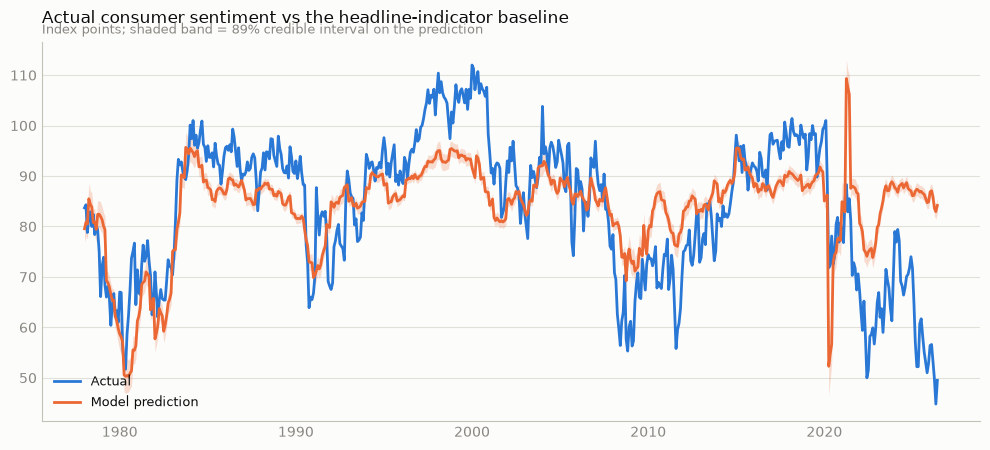

In [4]:
import matplotlib as mpl, matplotlib.pyplot as plt

SURF, INK, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'
mpl.rcParams.update({'font.family': ['Helvetica', 'DejaVu Sans'], 'font.size': 10})

fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=SURF)
ax.set_facecolor(SURF)
ax.grid(axis='y', color=GRID, lw=.8, zorder=0); ax.set_axisbelow(True)

ax.fill_between(s.index, mlo, mhi, color=ORANGE, alpha=.22, lw=0, zorder=2)
ax.plot(s.index, y,  color=BLUE,   lw=2, zorder=3, label='Actual')
ax.plot(s.index, mu, color=ORANGE, lw=2, zorder=4, label='Model prediction')

for sp in ('top','right'):   ax.spines[sp].set_visible(False)
for sp in ('left','bottom'): ax.spines[sp].set_color(AXIS)
ax.tick_params(colors=MUTED, length=0)

leg = ax.legend(frameon=False, loc='lower left', fontsize=9.5)
for t in leg.get_texts(): t.set_color(INK)

ax.set_title("Actual consumer sentiment vs the headline-indicator baseline",
             color=INK, fontsize=12, loc='left', pad=14)
ax.text(0, 1.015, "Index points; shaded band = 89% credible interval on the prediction",
        transform=ax.transAxes, color=MUTED, fontsize=9.5, va='bottom')

fig.tight_layout()
fig.savefig('pred_vs_actual.png', dpi=200, facecolor=SURF)